# Pseudotime Trajectory Inference

## Imports

In [1]:
import sys
from pathlib import Path

import anndata as ad
import anndata2ri
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from rpy2.robjects.packages import importr

# src/ on path for the shared `trajectory_inference` package (bare imports,
# same convention as `4. RNA Velocity.ipynb` — see docs/chat-notes-veloBench.md
# §17/§18). Repo root is separately, implicitly on path via Jupyter's cwd —
# used by `from markers import ...` and the `src.utils.*` imports elsewhere
# in this notebook (untouched inline logic, not yet synced — see §17).
_SRC = Path.cwd() / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

%load_ext rpy2.ipython
anndata2ri.set_ipython_converter()

# One global figure theme for the whole notebook (STREAM's `set_figure_params`
# does this once via `sns.set(...)`, so every later plot — STREAM's own,
# seaborn, or bare matplotlib — inherits it). We reuse the same defaults here
# so scanpy plots, networkx plots, and `plot_streamlike` all share one look
# instead of each falling back to its own library defaults.
sns.set_theme(
    context="notebook",
    style="white",
    palette="deep",
    font="sans-serif",
    font_scale=1.1,
    color_codes=True,
    rc={
        "figure.dpi": 120,
        "savefig.dpi": 150,
        "figure.figsize": [5.4, 4.8],
        "image.cmap": "viridis",
        "lines.markersize": 6,
        "legend.columnspacing": 0.1,
        "legend.borderaxespad": 0.1,
        "legend.handletextpad": 0.1,
    },
)

In [2]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd() / "src"))
from pipeline_config import load_config

cfg = load_config()  # dataset wybierasz w pipeline_config.toml (`active`) albo env BOOLAI_DATASET
print(cfg.describe())

dataset='hsc_4ds' [single dataset (no 1. Cell Annotation / 2. Data Integration)], samples=['young_A', 'young_B', 'old_A', 'old_B'], method='paga_dpt'


In [ ]:
%%R
library(SingleCellExperiment)
library(slingshot)
library(RaceID)

cat("R OK\n")
sessionInfo()

Exception ignored from cffi callback <function _processevents at 0x130897060>:
Traceback (most recent call last):
  File "/Users/jasiek/anaconda3/envs/scrna-ti/lib/python3.11/site-packages/rpy2/rinterface_lib/callbacks.py", line 308, in _processevents
    @ffi_proxy.callback(ffi_proxy._processevents_def,
    
KeyboardInterrupt: 


### Data Loading

In [3]:
adata = sc.read_h5ad(cfg.path("merged_h5ad"))
adata

AnnData object with n_obs × n_vars = 2604 × 15176
    obs: 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'

## Common preprocessing

In [4]:
# Metadata from Cell Annotation (+ optional Hérault paper columns for Layer B)
meta = pd.read_csv(cfg.path("cell_annotation_tsv"), sep="\t", index_col=0)
assert meta.index.equals(adata.obs_names) or meta.index.isin(adata.obs_names).all()
adata.obs = adata.obs.join(meta[["label", "label_color", "leiden", "discard"]], how="left")

if cfg.paper_metadata_path is not None:
    # ground truth z artykułu — tylko dla datasetów, które mają `paper_metadata` w configu
    batch_to_sample = {
        "young_A": "young_A",
        "young_B": "young_B",
        "old_A": "aged_A",
        "old_B": "aged_B",
    }
    _barcode = pd.Index(adata.obs_names).str.replace(r"_\d+$", "", regex=True)
    _sample = adata.obs["batch"].astype(str).map(batch_to_sample)
    _paper_key = pd.Index(_sample.to_numpy() + "_" + _barcode.to_numpy())

    paper = pd.read_csv(
        cfg.paper_metadata_path,
        usecols=["barcode", "sampleName", "HSPC_state", "Pseudotime", "hscScore", "Monocle_state"],
    )
    paper = paper.assign(paper_key=paper["sampleName"].astype(str) + "_" + paper["barcode"].astype(str))
    paper = paper.drop_duplicates("paper_key").set_index("paper_key")
    paper_aligned = paper.reindex(_paper_key)
    paper_aligned.index = adata.obs_names
    adata.obs["paper_state"] = paper_aligned["HSPC_state"].values
    adata.obs["paper_pseudotime"] = paper_aligned["Pseudotime"].values
    adata.obs["hscScore"] = paper_aligned["hscScore"].values
    adata.obs["monocle_state"] = paper_aligned["Monocle_state"].values
else:
    # brak ground truth z artykułu: kolumny zostają puste, reszta notebooka je pomija
    for _col in ("paper_state", "paper_pseudotime", "hscScore", "monocle_state"):
        adata.obs[_col] = np.nan

n_before = adata.n_obs
adata = adata[~adata.obs["discard"].fillna(False).astype(bool)].copy()
print(f"Dropped discard=True: {n_before - adata.n_obs} cells → {adata.n_obs} left")
print("labels:", adata.obs["label"].value_counts().to_dict())
print("paper_state:", adata.obs["paper_state"].value_counts(dropna=False).head(12).to_dict())

Dropped discard=True: 0 cells → 2604 left
labels: {'RPC': 940, 'RGC': 706, 'AC': 312, 'NB2': 312, 'NB1': 177, 'Cones': 157}
paper_state: {nan: 2604}


### Layer A — biological priors from labels

Recycled from `markers.py` / annotation metadata (no marker-score medoid).
`root_state`, `terminal_states`, `transient_states` come from the Hérault state hierarchy;
grouping uses `label` (`cell_type`).

In [5]:
from markers_retinal import states_and_markers

# stany z pipeline_config.toml (domyślnie hierarchia Hérault; dla innych datasetów nadpisz w configu)
ROOT_CANDIDATES = cfg.root_candidates  # initial / quiescent; prefer the first present
TERMINAL_STATES = cfg.terminal_states
TRANSIENT_STATES = cfg.transient_states

adata.obs["cell_type"] = adata.obs["label"].astype("category")
adata.obs["label"] = adata.obs["cell_type"]

present = set(adata.obs["label"].dropna().astype(str).unique())
root_state = next((s for s in ROOT_CANDIDATES if s in present), None)
if root_state is None:
    raise ValueError(f"No root candidate in labels {sorted(present)}; tried {ROOT_CANDIDATES}")

terminal_states = [s for s in TERMINAL_STATES if s in present]
transient_states = [s for s in TRANSIENT_STATES if s in present and s != root_state]

# Paper taxonomy (full Hérault set) — useful when annotation collapsed terminals
paper_present = set(adata.obs["paper_state"].dropna().astype(str).unique())
paper_root_state = next((s for s in ROOT_CANDIDATES if s in paper_present), None)
paper_terminals = [s for s in TERMINAL_STATES if s in paper_present]

adata.uns["root_state"] = root_state
adata.uns["terminal_states"] = terminal_states
adata.uns["transient_states"] = transient_states
adata.uns["ti_priors"] = {
    "layer": "A",
    "root_state": root_state,
    "terminal_states": terminal_states,
    "transient_states": transient_states,
    "root_candidates": list(ROOT_CANDIDATES),
    "states_and_markers_keys": list(states_and_markers),
    "paper_root_state": paper_root_state,
    "paper_terminal_states": paper_terminals,
}

print("root_state:", root_state, f"(n={int((adata.obs['label'] == root_state).sum())})")
print("terminal_states:", terminal_states)
print("transient_states:", transient_states)
print("paper_root_state:", paper_root_state, "| paper_terminals:", paper_terminals)
adata.uns["ti_priors"]

root_state: RPC (n=940)
terminal_states: []
transient_states: []
paper_root_state: None | paper_terminals: []


{'layer': 'A',
 'root_state': 'RPC',
 'terminal_states': [],
 'transient_states': [],
 'root_candidates': ['RPC'],
 'states_and_markers_keys': ['RPC', 'NB1', 'NB2', 'RGC', 'AC', 'HC', 'Cones'],
 'paper_root_state': None,
 'paper_terminal_states': []}

### Spójna paleta kolorów fenotypów

STREAM cache'uje kolor per kategoria raz (`adata.uns['<ann>_color']`) i używa go
we wszystkich kolejnych wykresach. U nas metadane z Cell Annotation już niosą
kanoniczny kolor per fenotyp (`obs['label_color']`) — wystarczy go raz przepisać
do `uns`, żeby scanpy (`uns['label_colors']`, forma listy) i nasze własne wykresy
/ `plot_streamlike` (`uns['label_color']`, forma dict) używały tego samego koloru
dla danego stanu, zamiast każdy generował swoją paletę osobno.

In [6]:
adata.obs["label"] = adata.obs["label"].astype("category")
_categories = list(adata.obs["label"].cat.categories)
_label_palette = (
    adata.obs[["label", "label_color"]]
    .dropna()
    .drop_duplicates("label")
    .set_index("label")["label_color"]
    .astype(str)
    .to_dict()
)
_missing = [c for c in _categories if c not in _label_palette]
if _missing:
    _fallback = sns.color_palette("deep", n_colors=len(_missing)).as_hex()
    _label_palette.update(dict(zip(_missing, _fallback)))
    print(f"WARNING: no label_color for {_missing}; used fallback palette")

adata.uns["label_color"] = _label_palette  # dict — plot_streamlike / our own plots
adata.uns["label_colors"] = [_label_palette[c] for c in _categories]  # scanpy convention (sc.pl.*)

_label_palette

{'RPC': '#66c2a5',
 'RGC': '#fc8d62',
 'AC': '#8da0cb',
 'Cones': '#e78ac3',
 'NB2': '#a6d854',
 'NB1': '#ffd92f'}

### Layer B — root cell for APIs that need it (DPT `iroot`, etc.)

1. Prefer medoid of `root_state` cells in integrated embedding (`X_emb` → `X_pca`, else existing `X_pca`).
2. If no embedding yet: use paper `hscScore` (argmax) / `paper_pseudotime` (argmin) within `root_state`.
3. Store `uns['root_cell']` and integer `uns['iroot']` for scanpy.

Brak `X_emb`/`X_pca` → PCA liczone z `pca_from_corrected` na tej samej reprezentacji co UMAP w
`3. Final Cell Annotation` (`corrected_h5ad`: HVG, lognorm, scale), **nie** na surowych countach z
`merged_h5ad` — PCA na countach odzwierciedla głównie rozmiar biblioteki i miesza stany (np. AC/Cones).

In [7]:
from scipy.spatial.distance import cdist


def pca_from_corrected(adata, n_comps=50):
    """`X_pca` z `corrected_h5ad` (reprezentacja z 3. Final Cell Annotation), wyrównane do `adata.obs_names`."""
    corrected_path = cfg.path("corrected_h5ad")
    if not corrected_path.exists():
        raise FileNotFoundError(f"{corrected_path} not found — run '3. Final Cell Annotation.ipynb' first")
    corrected = sc.read_h5ad(corrected_path)
    missing = adata.obs_names.difference(corrected.obs_names)
    if len(missing):
        raise ValueError(f"{len(missing)} cells missing from {corrected_path.name}, e.g. {list(missing[:3])}")
    corrected = corrected[adata.obs_names].copy()
    sc.pp.pca(corrected, n_comps=min(n_comps, corrected.n_vars - 1))
    adata.obsm["X_pca"] = corrected.obsm["X_pca"]
    print(f"X_pca: {adata.obsm['X_pca'].shape[1]} PCs from {corrected_path.name} ({corrected.n_vars} genes)")


root_mask = adata.obs["label"].astype(str) == adata.uns["root_state"]
root_idx = np.where(root_mask.to_numpy())[0]
if root_idx.size == 0:
    raise ValueError(f"No cells with label == {adata.uns['root_state']!r}")

# Embedding for medoid (plan: X_emb copied to X_pca for anndata2ri / Slingshot)
if "X_emb" in adata.obsm:
    adata.obsm["X_pca"] = np.asarray(adata.obsm["X_emb"])
emb_key = "X_pca" if "X_pca" in adata.obsm else None

_root_scores = adata.obs.loc[root_mask, ["hscScore", "paper_pseudotime"]]
if emb_key is None and not _root_scores.notna().any().any():
    # no paper scores for this dataset: fall back to the medoid of root cells in PCA space
    pca_from_corrected(adata, n_comps=50)
    emb_key = "X_pca"

root_cell = None
root_method = None

if emb_key is not None:
    coords = np.asarray(adata.obsm[emb_key])[root_idx]
    centroid = coords.mean(axis=0, keepdims=True)
    medoid_local = int(cdist(coords, centroid).argmin())
    root_cell = adata.obs_names[root_idx[medoid_local]]
    root_method = f"medoid:{emb_key}"
else:
    sub = adata.obs.loc[root_mask, ["hscScore", "paper_pseudotime"]].copy()
    if sub["hscScore"].notna().any():
        root_cell = sub["hscScore"].astype(float).idxmax()
        root_method = "argmax:hscScore"
    elif sub["paper_pseudotime"].notna().any():
        root_cell = sub["paper_pseudotime"].astype(float).idxmin()
        root_method = "argmin:paper_pseudotime"
    else:
        root_cell = adata.obs_names[root_idx[0]]
        root_method = "fallback:first_root_cell"
        print("WARNING: no embedding and no paper scores; using first root cell")

iroot = int(adata.obs_names.get_loc(root_cell))
adata.uns["root_cell"] = root_cell
adata.uns["iroot"] = iroot
adata.uns["ti_priors_B"] = {
    "layer": "B",
    "root_cell": root_cell,
    "iroot": iroot,
    "method": root_method,
    "n_root_cells": int(root_idx.size),
    "embedding_key": emb_key,
}

# Convenience aliases for later adapters
start_cluster = adata.uns["root_state"]
start_id = root_cell
end_clusters = list(adata.uns["terminal_states"])

print(f"root_cell={root_cell!r}  iroot={iroot}  via {root_method}")
print(f"start_cluster={start_cluster!r}  end_clusters={end_clusters}")
if root_cell in adata.obs.index:
    print(adata.obs.loc[root_cell, ["label", "paper_state", "hscScore", "paper_pseudotime"]])
adata.uns["ti_priors_B"]

X_pca: 50 PCs from integrated_combat_corrected_expression.h5ad (731 genes)
root_cell='Lane1_TACTTGTGTTTACTCT'  iroot=2084  via medoid:X_pca
start_cluster='RPC'  end_clusters=[]
label               RPC
paper_state         NaN
hscScore            NaN
paper_pseudotime    NaN
Name: Lane1_TACTTGTGTTTACTCT, dtype: object


{'layer': 'B',
 'root_cell': 'Lane1_TACTTGTGTTTACTCT',
 'iroot': 2084,
 'method': 'medoid:X_pca',
 'n_root_cells': 940,
 'embedding_key': 'X_pca'}

## Inference

### PAGA

In [8]:
# PAGA + DPT (jak tests/test_ti_methods_smoke.py), z iroot z Layer B
if "X_emb" in adata.obsm and "X_pca" not in adata.obsm:
    adata.obsm["X_pca"] = np.asarray(adata.obsm["X_emb"])
if "X_pca" not in adata.obsm:
    pca_from_corrected(adata, n_comps=50)  # Layer B; not raw counts

sc.pp.neighbors(adata, n_neighbors=15, use_rep="X_pca")
sc.tl.paga(adata, groups="label")
# adata.uns["iroot"] already set in Layer B
sc.tl.diffmap(adata)
sc.tl.dpt(adata)

adata.obs["pseudotime"] = adata.obs["dpt_pseudotime"]
adata.obs["branch"] = adata.obs["label"].astype("category")
print("dpt_pseudotime:", adata.obs["dpt_pseudotime"].describe()[["min", "50%", "max"]].to_dict())
adata.obs[["label", "dpt_pseudotime"]].groupby("label", observed=True)["dpt_pseudotime"].median().sort_values()

dpt_pseudotime: {'min': 0.0, '50%': 0.30059781670570374, 'max': 1.0}


label
RPC      0.033064
NB1      0.094229
NB2      0.293397
AC       0.469394
Cones    0.551316
RGC      0.831792
Name: dpt_pseudotime, dtype: float32

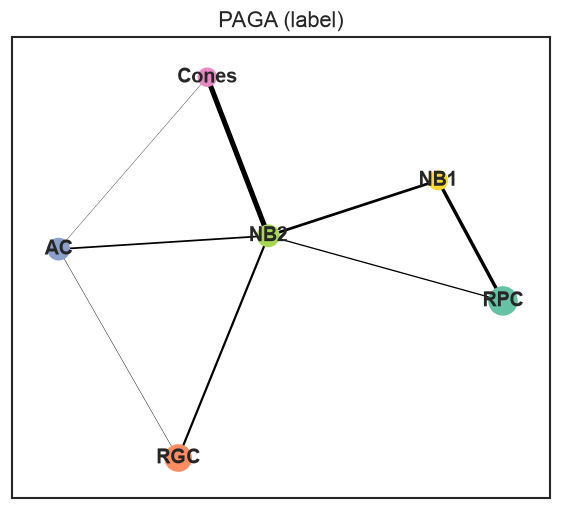

In [9]:
# quick peek; full figures in Results analysis
sc.pl.paga(adata, color="label", title="PAGA (label)", show=True)


## Results analysis

Wizualizacje **bez pełnego STREAM** (scanpy / matplotlib / networkx + `plot_streamlike`):

| STREAM | Tutaj |
|---|---|
| `plot_dimension_reduction` (label) | UMAP: `label`, `pseudotime`, `branch` |
| embedding + markery | UMAP z markerami z `states_and_markers` |
| graf na embeddingu | PAGA (+ PAGA na UMAP) |
| flat tree (topologia) | graf stanów z medianą `pseudotime` |
| KDE + Q1/Q3 | KDE `pseudotime` |
| stream / subway | `plot_streamlike` (`src/utils/plot_streamlike.py`) |

Bez QC (`plot_qc`). Figury → `results/{method}/figures/`.


In [10]:
from pathlib import Path
import matplotlib.pyplot as plt

METHOD = cfg.method
FIGURES_DIR = cfg.results_dir() / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# ensure embedding + contract aliases
if "X_umap" not in adata.obsm:
    sc.tl.umap(adata)
adata.obsm["X_plot"] = np.asarray(adata.obsm["X_umap"])
if "pseudotime" not in adata.obs and "dpt_pseudotime" in adata.obs:
    adata.obs["pseudotime"] = adata.obs["dpt_pseudotime"]
if "branch" not in adata.obs:
    adata.obs["branch"] = adata.obs["label"].astype("category")

print("FIGURES_DIR =", FIGURES_DIR.resolve())


FIGURES_DIR = /Users/jasiek/ideas/boolai/results/hsc_4ds/paga_dpt/figures


### Embedding (UMAP) — label / pseudotime / branch


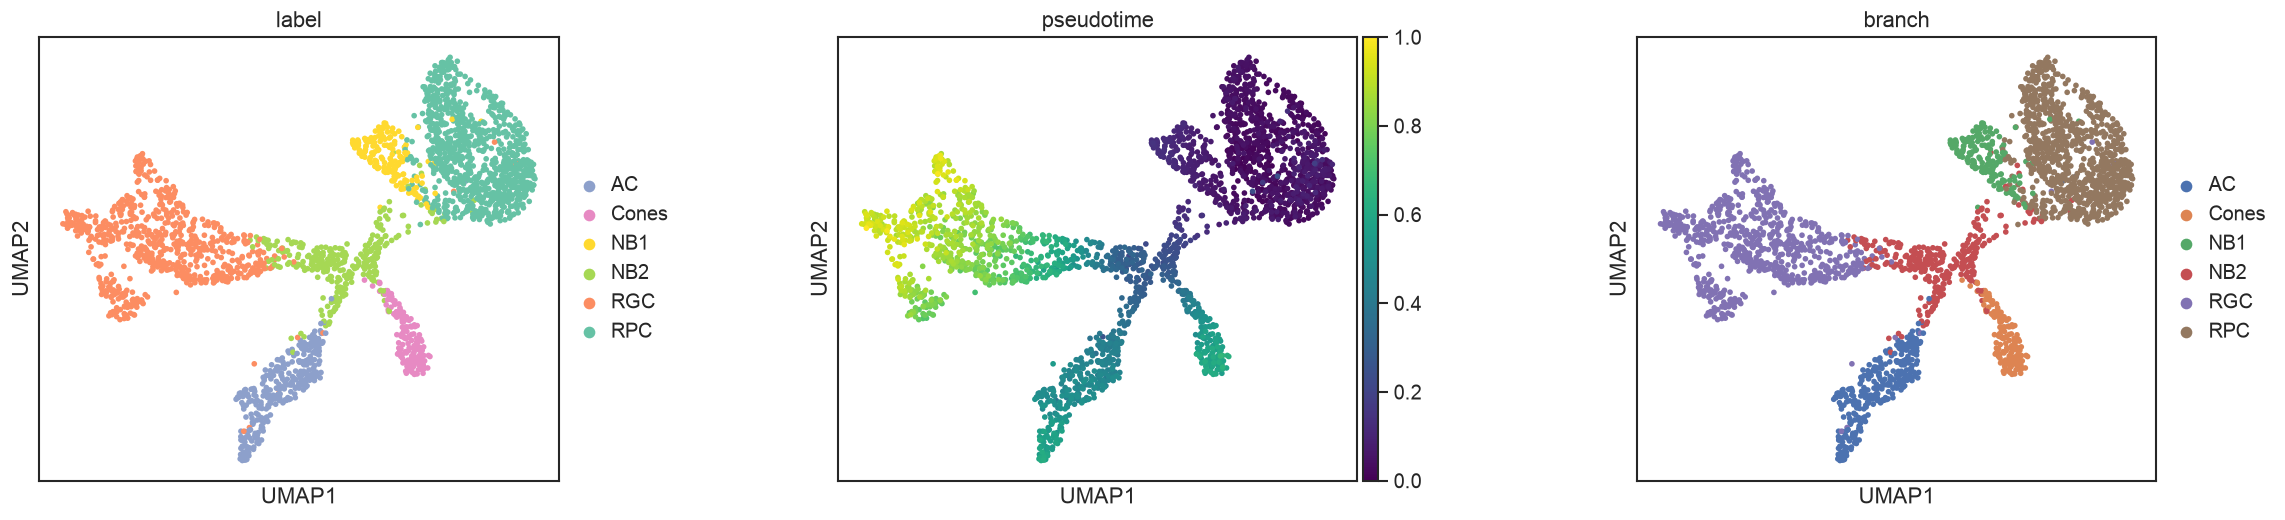

In [11]:
sc.settings.figdir = str(FIGURES_DIR)
sc.pl.umap(
    adata,
    color=["label", "pseudotime", "branch"],
    wspace=0.4,
    show=True,
    save="_label_pseudotime_branch.png",
)
plt.show()


### Embedding + markery fenotypowe

Jak w STREAM (`plot_dimension_reduction` z markerami Cones/NB1) — tu markery z `states_and_markers` obecne w `adata.var_names`.


In [12]:
from data_prep import normalize_log_scanpy
from markers import states_and_markers
from trajectory_inference import plot_marker_genes

sc.settings.figdir = str(FIGURES_DIR)

# adata.X holds raw counts (merged_h5ad) — plot log-normalized expression, same normalization as 3. Final Cell Annotation
if "lognorm" not in adata.layers:
    _lognorm = ad.AnnData(adata.X.astype(np.float32))
    normalize_log_scanpy(_lognorm)
    adata.layers["lognorm"] = _lognorm.X

_plot_genes = plot_marker_genes(
    adata,
    states_and_markers,
    priority_states=[
        adata.uns.get("root_state"),
        *adata.uns.get("terminal_states", []),
        *adata.uns.get("transient_states", []),
    ],
    layer="lognorm",
    wspace=0.35,
    ncols=4,
    show=True,
    save="_markers.png",
)
if not _plot_genes:
    print("No marker genes from states_and_markers found in var_names; skip")
else:
    print("plotting markers:", _plot_genes)
    plt.show()

No marker genes from states_and_markers found in var_names; skip


### Graf trajektorii — PAGA (+ nakładka na UMAP)


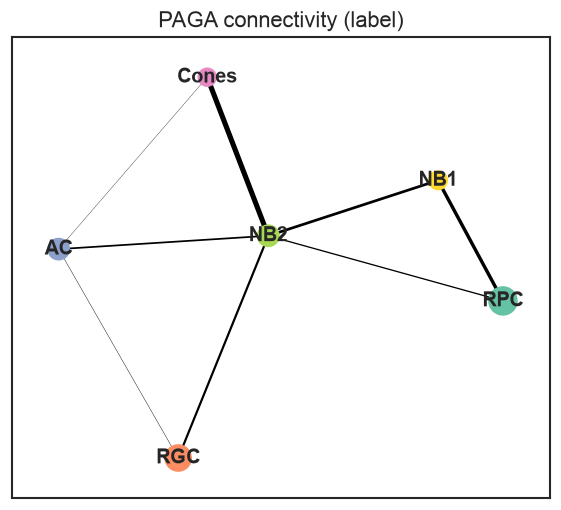

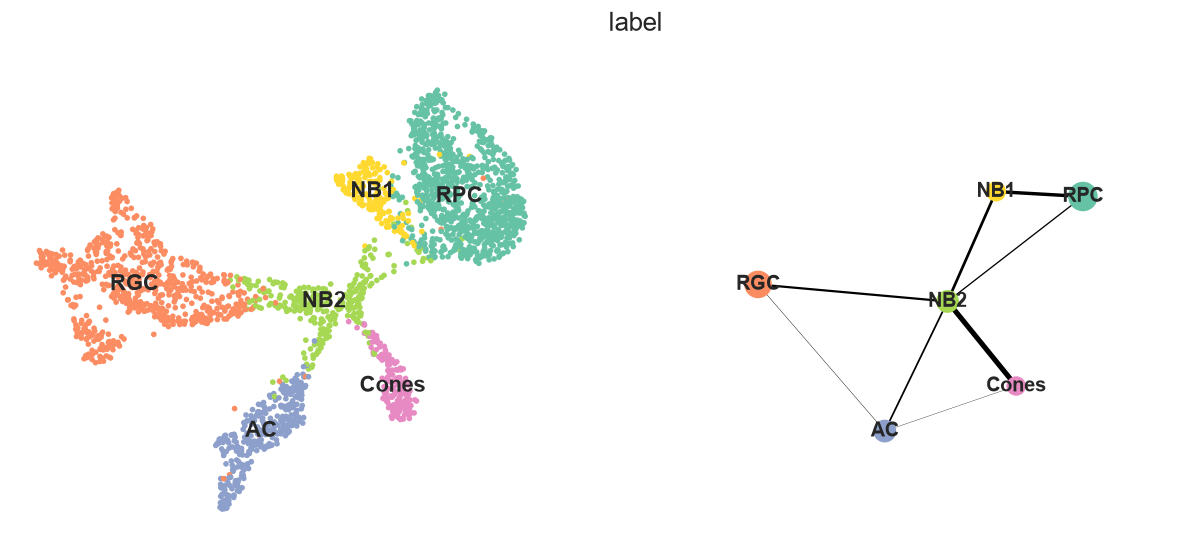

saved under /Users/jasiek/ideas/boolai/results/hsc_4ds/paga_dpt/figures


In [13]:
sc.settings.figdir = str(FIGURES_DIR)

# abstract PAGA graph
sc.pl.paga(
    adata,
    color="label",
    title="PAGA connectivity (label)",
    show=True,
    save="_connectivity.png",
)
plt.show()

# PAGA positioned on UMAP
sc.pl.paga_compare(
    adata,
    basis="umap",
    color="label",
    frameon=False,
    show=True,
    save="_umap.png",
)
plt.show()
print("saved under", FIGURES_DIR)


### Flat-tree–like — stany vs mediana pseudoczasu

Uproszczony odpowiednik `plot_flat_tree`: węzły = `label`, pozycja x = mediana `pseudotime`,
krawędzie z realnej topologii PAGA (`connectivities_tree`, `src/utils/trajectory_graph.py`)
— nie z rankingu po medianie pseudoczasu (fallback tylko gdy PAGA niedostępne).


state graph topology source: paga


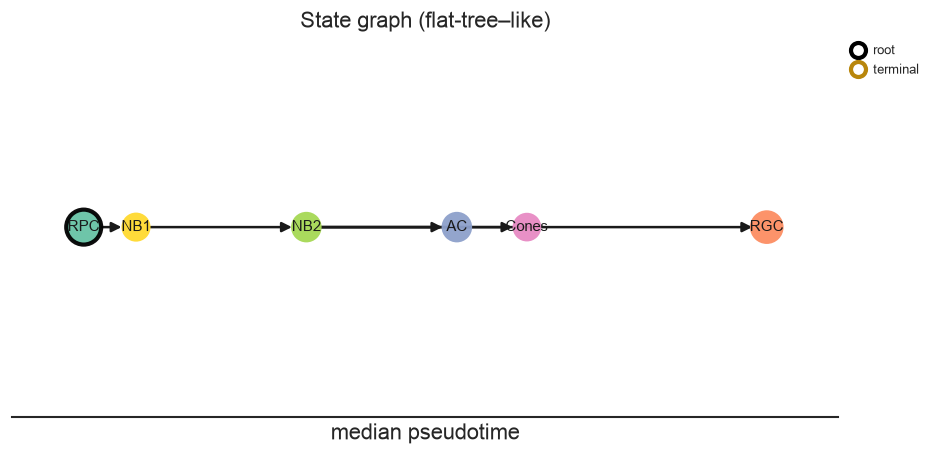

edges: [('RPC', 'NB1'), ('NB1', 'NB2'), ('NB2', 'AC'), ('NB2', 'Cones'), ('NB2', 'RGC')]


In [14]:
import networkx as nx

from src.utils.trajectory_graph import derive_trajectory_graph

pt_key = "pseudotime"
med = (
    adata.obs.groupby("label", observed=True)[pt_key]
    .median()
    .astype(float)
    .sort_values()
)
counts = adata.obs["label"].astype(str).value_counts()
palette = adata.uns.get("label_color", {})

terminals = set(map(str, adata.uns.get("terminal_states", [])))
root = str(adata.uns.get("root_state"))
states = [str(s) for s in med.index]

# real topology: PAGA connectivity tree (fallback: median-pt chain if no PAGA)
tree, root, edge_source = derive_trajectory_graph(
    adata,
    root=root,
    state_key="label",
    pt_key=pt_key,
    terminal_states=adata.uns.get("terminal_states"),
)
edges = list(tree.edges())
print(f"state graph topology source: {edge_source}")

G = nx.DiGraph()
G.add_nodes_from(states)
G.add_edges_from(edges)

pos = {s: (float(med[s]), 0.0) for s in states if s not in terminals}
term = [s for s in states if s in terminals]
if term:
    ys = np.linspace(-1, 1, num=len(term)) if len(term) > 1 else [0.0]
    for t, y in zip(term, ys):
        pos[t] = (float(med[t]), float(y))

fig, ax = plt.subplots(figsize=(8, 4))
nx.draw_networkx_edges(G, pos, ax=ax, arrows=True, arrowstyle="-|>", arrowsize=12, width=1.5)
# fill = canonical phenotype color (adata.uns['label_color'], same as UMAP/PAGA/plot_streamlike);
# root/terminal are marked via border, not by overriding the phenotype's own color
node_fill = [palette.get(s, "#1f77b4") for s in G.nodes]
node_edge = ["black" if s == root else ("#b8860b" if s in terminals else "white") for s in G.nodes]
node_lw = [2.5 if (s == root or s in terminals) else 0.0 for s in G.nodes]
sizes = [200 + 8 * int(counts.get(s, 0) ** 0.5) for s in G.nodes]
nx.draw_networkx_nodes(
    G, pos, ax=ax, node_color=node_fill, edgecolors=node_edge, linewidths=node_lw,
    node_size=sizes, alpha=0.95,
)
nx.draw_networkx_labels(G, pos, ax=ax, font_size=9)
ax.set_xlabel(f"median {pt_key}")
ax.set_yticks([])
ax.set_title("State graph (flat-tree–like)")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
_legend_handles = [
    plt.Line2D([0], [0], marker="o", color="none", markerfacecolor="none",
               markeredgecolor="black", markeredgewidth=2.5, markersize=9, label="root"),
    plt.Line2D([0], [0], marker="o", color="none", markerfacecolor="none",
               markeredgecolor="#b8860b", markeredgewidth=2.5, markersize=9, label="terminal"),
]
ax.legend(handles=_legend_handles, loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "state_graph_flat_tree_like.png", dpi=150, bbox_inches="tight")
plt.show()

# authoritative trajectory topology for downstream plots (plot_streamlike) and BoNesis export
adata.uns["trajectory_edges"] = [list(e) for e in edges]
print("edges:", edges)


### Pseudotime — KDE (+ Q1/Q3) i rozkład per `label`

Odpowiednik KDE z notebooka 2 przed wyborem obserwacji Q1–Q3.


/var/folders/t2/dm2tmtgs4cjf2zw8zr0v8fpr0000gn/T/ipykernel_83890/1124323656.py:31: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(data, tick_labels=order, vert=True, showfliers=False)


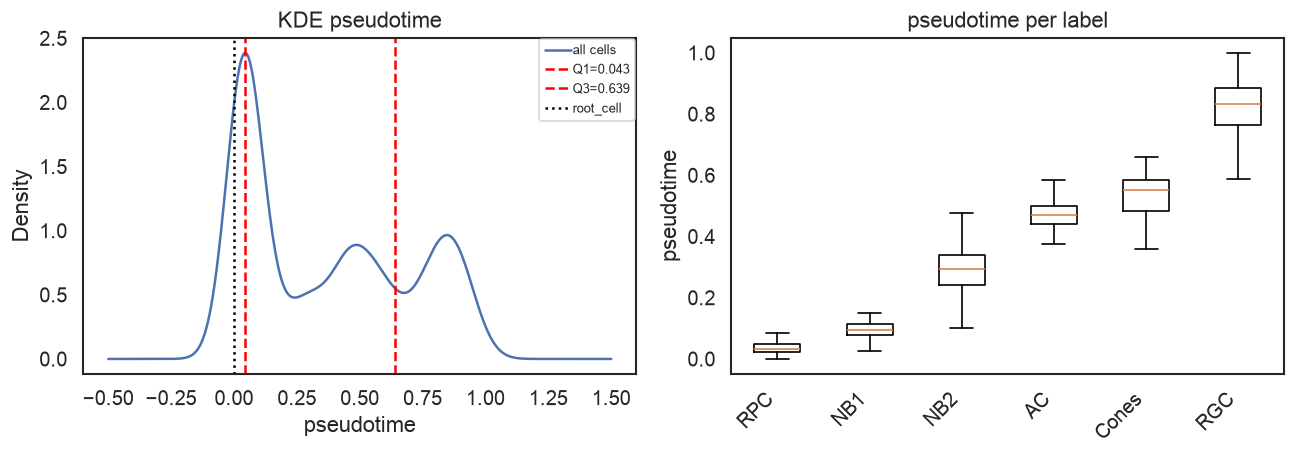

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

pt = adata.obs["pseudotime"].astype(float)
pt = pt[np.isfinite(pt)]
pt.plot.kde(ax=axes[0], label="all cells")
q1, q3 = float(pt.quantile(0.25)), float(pt.quantile(0.75))
axes[0].axvline(q1, color="red", ls="--", label=f"Q1={q1:.3g}")
axes[0].axvline(q3, color="red", ls="--", label=f"Q3={q3:.3g}")
if "root_cell" in adata.uns and adata.uns["root_cell"] in adata.obs_names:
    axes[0].axvline(
        float(adata.obs.loc[adata.uns["root_cell"], "pseudotime"]),
        color="black",
        ls=":",
        label="root_cell",
    )
axes[0].set_xlabel("pseudotime")
axes[0].set_title("KDE pseudotime")
axes[0].legend(fontsize=8)

order = (
    adata.obs.groupby("label", observed=True)["pseudotime"]
    .median()
    .sort_values()
    .index.astype(str)
    .tolist()
)
plot_df = adata.obs[["label", "pseudotime"]].copy()
plot_df["label"] = plot_df["label"].astype(str)
# boxen-like: boxplot ordered by median pt
data = [plot_df.loc[plot_df["label"] == lab, "pseudotime"].astype(float).to_numpy() for lab in order]
axes[1].boxplot(data, tick_labels=order, vert=True, showfliers=False)
axes[1].set_xticklabels(order, rotation=45, ha="right")
axes[1].set_ylabel("pseudotime")
axes[1].set_title("pseudotime per label")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "pseudotime_kde_box.png", dpi=150, bbox_inches="tight")
plt.show()


### Stream / subway — `plot_streamlike`

Reimplementacja layoutu STREAM (`plot_stream_sc` / `add_stream_sc_pos`) na kontrakcie §12.5 — bez `flat_tree` / EPG.


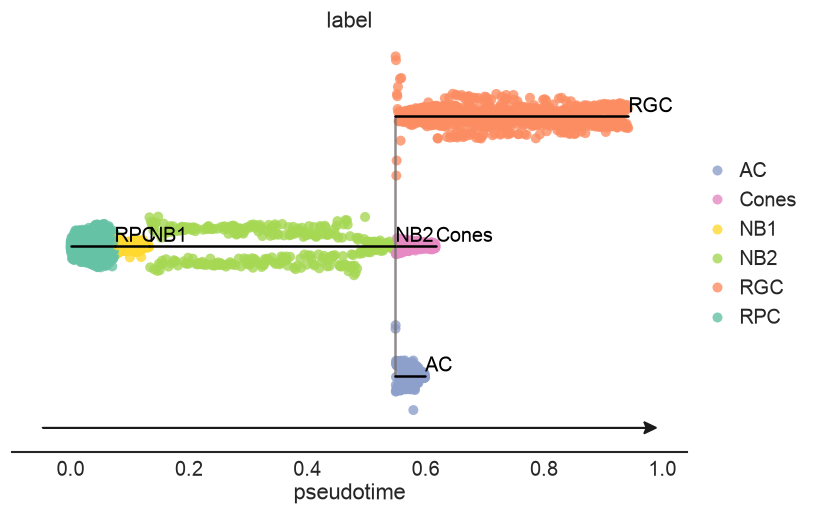

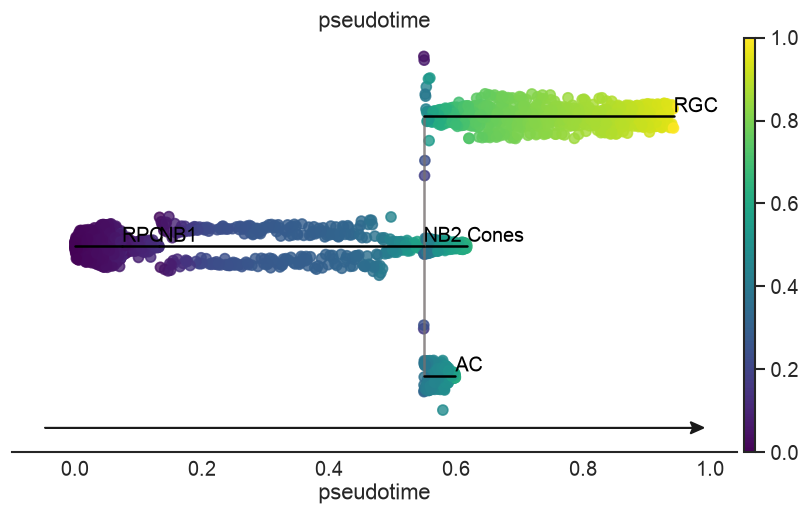

[<Figure size 840x540 with 1 Axes>, <Figure size 840x540 with 2 Axes>]

In [16]:
import sys
from pathlib import Path

_ROOT = Path.cwd()
if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))

from src.utils.plot_streamlike import plot_streamlike

plot_streamlike(
    adata,
    root=adata.uns.get("root_state"),
    color=["label", "pseudotime"],
    state_key="label",
    pt_key="pseudotime",
    edges=adata.uns.get("trajectory_edges"),
    show_graph=True,
    show_text=True,
    save_fig=True,
    fig_path=FIGURES_DIR,
    fig_format="png",
    show=True,
)


### Sanity: nasz `pseudotime` vs paper `paper_pseudotime` (jeśli dostępny)


In [17]:
from trajectory_inference import plot_pseudotime_comparison

if "paper_pseudotime" in adata.obs and adata.obs["paper_pseudotime"].notna().any():
    ax, rho = plot_pseudotime_comparison(
        adata,
        "paper_pseudotime",
        "pseudotime",
        x_label="paper_pseudotime (Hérault)",
        y_label="pseudotime (DPT)",
    )
    ax.figure.tight_layout()
    ax.figure.savefig(FIGURES_DIR / "pseudotime_vs_paper.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("paper_pseudotime unavailable — skip")


paper_pseudotime unavailable — skip


### Save results

Wspólna końcówka (§12.6–12.8 w `docs/stream_trajectory_inference_skrot.md`), funkcje ze wspólnego `src/trajectory_inference/` (te same co w `4. RNA Velocity.ipynb`):

1. `select_observations` — per `label` komórki z `pseudotime` w Q1–Q3 (bez `node` EPG)
2. `derive_bonesis_constraints` — więzy BoNesis z drzewa stanów (tylko stany z CSV): łańcuchy `>=` wzdłuż krawędzi, `fixed` na liściach, commitment `/` i uniwersalne `>> "fixpoints"` (reguły: `src/trajectory_inference/README.md`)
3. zapis `results/{method}/` (`trajectory.h5ad`, CSV, `transition_constraints.{txt,json}`)

In [18]:
from pathlib import Path

from trajectory_inference import (
    derive_bonesis_constraints,
    select_observations,
    write_bonesis_constraints,
)

METHOD = cfg.method
RESULTS_DIR = cfg.results_dir()
FIGURES_DIR = globals().get("FIGURES_DIR", RESULTS_DIR / "figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("RESULTS_DIR =", RESULTS_DIR.resolve())
print("helpers: select_observations, derive_bonesis_constraints (src/trajectory_inference)")

RESULTS_DIR = /Users/jasiek/ideas/boolai/results/hsc_4ds/paga_dpt
helpers: select_observations, derive_bonesis_constraints (src/trajectory_inference)


#### 1. `select_observations` → CSV

In [19]:
observations = select_observations(adata, pt_key="pseudotime", label_key="label")
obs_csv = RESULTS_DIR / "pseudotime_inferred_observations.csv"
observations.to_frame().to_csv(obs_csv)

print(f"Wrote {obs_csv}  (n={len(observations)})")
print(observations.value_counts().to_string())
observations.head()

Wrote /Users/jasiek/ideas/boolai/results/hsc_4ds/paga_dpt/pseudotime_inferred_observations.csv  (n=1302)
observation
RPC      470
RGC      352
AC       156
NB2      156
NB1       89
Cones     79


Lane1_AAACGGGGTGTTGAGG    AC
Lane1_AAATGCCGTTATCCGA    AC
Lane1_AAGACCTAGGGTGTTG    AC
Lane1_ACAGCTAAGAGCAATT    AC
Lane1_ACATACGCAAGAGGCT    AC
Name: observation, dtype: object

#### 2. `derive_bonesis_constraints` → txt + json

In [20]:
constraints = derive_bonesis_constraints(
    adata,
    observations,
    method=METHOD,
    pt_key="pseudotime",
    label_key="label",
    terminal_states=list(adata.uns.get("terminal_states", [])),
)
txt_path, json_path = write_bonesis_constraints(constraints, RESULTS_DIR)

print(f"Wrote {txt_path}")
print(f"Wrote {json_path}")
print("terminals:", constraints["terminals"], "| side_leaves:", constraints["side_leaves"])
print("--- bonesis_lines ---")
for line in constraints["bonesis_lines"]:
    print(line)
constraints

Wrote /Users/jasiek/ideas/boolai/results/hsc_4ds/paga_dpt/transition_constraints.txt
Wrote /Users/jasiek/ideas/boolai/results/hsc_4ds/paga_dpt/transition_constraints.json
terminals: ['AC', 'Cones', 'RGC'] | side_leaves: []
--- bonesis_lines ---
fixed = {}
fixed["AC"] = bo.fixed(~bo.obs("AC"))
fixed["Cones"] = bo.fixed(~bo.obs("Cones"))
fixed["RGC"] = bo.fixed(~bo.obs("RGC"))
fixed["AC"] != fixed["Cones"]
fixed["AC"] != fixed["RGC"]
fixed["Cones"] != fixed["RGC"]
~bo.obs("RPC") >= ~bo.obs("NB1") >= ~bo.obs("NB2") >= fixed["AC"]
~bo.obs("NB2") >= fixed["Cones"]
~bo.obs("NB2") >= fixed["RGC"]
~bo.obs("RPC") >> "fixpoints" ^ {bo.obs("AC"), bo.obs("Cones"), bo.obs("RGC")}


{'method': 'paga_dpt',
 'root': 'RPC',
 'terminals': ['AC', 'Cones', 'RGC'],
 'side_leaves': [],
 'edges': [['RPC', 'NB1'],
  ['NB1', 'NB2'],
  ['NB2', 'AC'],
  ['NB2', 'Cones'],
  ['NB2', 'RGC']],
 'chains': [['RPC', 'NB1', 'NB2', 'AC'], ['NB2', 'Cones'], ['NB2', 'RGC']],
 'nonreach': [],
 'universal': [['RPC', ['AC', 'Cones', 'RGC']]],
 'distinct': [['AC', 'Cones'], ['AC', 'RGC'], ['Cones', 'RGC']],
 'bonesis_lines': ['fixed = {}',
  'fixed["AC"] = bo.fixed(~bo.obs("AC"))',
  'fixed["Cones"] = bo.fixed(~bo.obs("Cones"))',
  'fixed["RGC"] = bo.fixed(~bo.obs("RGC"))',
  'fixed["AC"] != fixed["Cones"]',
  'fixed["AC"] != fixed["RGC"]',
  'fixed["Cones"] != fixed["RGC"]',
  '~bo.obs("RPC") >= ~bo.obs("NB1") >= ~bo.obs("NB2") >= fixed["AC"]',
  '~bo.obs("NB2") >= fixed["Cones"]',
  '~bo.obs("NB2") >= fixed["RGC"]',
  '~bo.obs("RPC") >> "fixpoints" ^ {bo.obs("AC"), bo.obs("Cones"), bo.obs("RGC")}'],
 'terminals_prior': [],
 'states_in_csv': ['AC', 'Cones', 'NB1', 'NB2', 'RGC', 'RPC'],
 'ed

#### 3. `trajectory.h5ad` (+ `X_plot`)

In [21]:
from trajectory_inference import write_trajectory_h5ad

h5ad_path = RESULTS_DIR / "trajectory.h5ad"
ad_ti = write_trajectory_h5ad(adata, h5ad_path, method=METHOD)  # slim AnnData: contract slots only
print(f"Wrote {h5ad_path}")
print("slots:", {
    "pseudotime": "pseudotime" in ad_ti.obs,
    "branch": "branch" in ad_ti.obs,
    "root_state": ad_ti.uns.get("root_state"),
    "terminal_states": ad_ti.uns.get("terminal_states"),
    "transient_order": ad_ti.uns.get("transient_order"),
    "X_plot": "X_plot" in ad_ti.obsm,
})
sorted(p.name for p in RESULTS_DIR.iterdir())

Wrote /Users/jasiek/ideas/boolai/results/hsc_4ds/paga_dpt/trajectory.h5ad
slots: {'pseudotime': True, 'branch': True, 'root_state': 'RPC', 'terminal_states': [], 'transient_order': ['RPC', 'NB1', 'NB2'], 'X_plot': True}


['figures',
 'pseudotime_inferred_observations.csv',
 'trajectory.h5ad',
 'transition_constraints.json',
 'transition_constraints.txt']